# Practical 2 — Huffman Encoding using a Greedy Strategy

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Write a program to implement **Huffman encoding** using a greedy strategy.

## 2. Problem statement

Given a set of characters and their frequencies, build an optimal binary
prefix code such that:

- every character maps to a unique binary codeword,
- no codeword is a prefix of another codeword,
- the total number of bits needed to encode the text is minimised.

Also implement encoding and decoding, and verify that the decoded text is
identical to the original.

## 3. Objectives

- Understand variable-length prefix codes and why they are unambiguous.
- Implement the greedy Huffman tree construction using a min-heap.
- Encode and decode a message and verify lossless compression.
- Analyse the time and space complexity of the algorithm.

## 4. Theory

### 4.1 Fixed-length vs variable-length codes

With 6 symbols, a fixed-length code needs $\lceil \log_2 6 \rceil = 3$ bits per
symbol. Huffman coding instead gives **short codes to frequent symbols** and
**long codes to rare symbols**, reducing the average length.

A **prefix code** guarantees that no codeword is a prefix of another. For
example, `{0, 10, 11}` is a prefix code; `{0, 01, 1}` is not, because `0` is a
prefix of `01`.

### 4.2 Greedy construction

1. Create one leaf node for each character, labelled with its frequency.
2. Insert all leaves into a min-heap keyed by frequency.
3. Repeatedly extract the two nodes with the smallest frequencies.
4. Create a new internal node whose frequency is the sum of the two.
5. Insert the new node back into the heap.
6. When only one node remains, it is the root of the Huffman tree.

Assign bit `0` to every left edge and bit `1` to every right edge. The path
from the root to a leaf gives that character's codeword.

### 4.3 Why the greedy choice is optimal

The two least frequent characters must be the deepest leaves in some optimal
tree. Merging them into one node does not change the optimality of the rest of
the problem, so the greedy choice is safe. This is the **exchange argument**
behind Huffman's algorithm.

### 4.4 Complexity

| Operation | Cost |
|---|---|
| Build heap | $O(n)$ |
| $n-1$ merge steps, each with two extracts and one insert | $O(n\log n)$ |
| Tree traversal to generate codes | $O(n)$ |
| Encoding a text of length $L$ | $O(L)$ |
| Decoding a bit stream of length $B$ | $O(B)$ |

**Time:** $O(n\log n)$ where $n$ is the number of distinct characters.  
**Space:** $O(n)$ for the tree, heap and code table.

In [1]:
import heapq
from collections import Counter
from itertools import count
import math
import textwrap

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
class HuffmanNode:
    """A node in the Huffman tree.

    Leaf nodes have a character; internal nodes have ``char = None``.
    ``order`` is a tie-breaker so that the heap never tries to compare two
    nodes with equal frequency (which would raise a TypeError).
    """

    _order = count()

    def __init__(self, char, frequency, left=None, right=None):
        self.char = char
        self.frequency = frequency
        self.left = left
        self.right = right
        self.order = next(HuffmanNode._order)

    def __lt__(self, other):
        return (self.frequency, self.order) < (other.frequency, other.order)

    def is_leaf(self):
        return self.left is None and self.right is None


def build_huffman_tree(frequencies: dict[str, int]) -> HuffmanNode:
    """Build and return the root of a Huffman tree."""
    if not frequencies:
        raise ValueError("At least one character is required")
    if any(frequency <= 0 for frequency in frequencies.values()):
        raise ValueError("Frequencies must be positive integers")

    heap = [HuffmanNode(char, frequency) for char, frequency in frequencies.items()]
    heapq.heapify(heap)

    if len(heap) == 1:
        return heap[0]

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        parent = HuffmanNode(
            None,
            left.frequency + right.frequency,
            left=left,
            right=right,
        )
        heapq.heappush(heap, parent)

    return heap[0]


def build_code_table(root: HuffmanNode) -> dict[str, str]:
    """Return a mapping from character to its Huffman codeword."""
    codes: dict[str, str] = {}

    def traverse(node: HuffmanNode, prefix: str) -> None:
        if node.is_leaf():
            # A single-symbol alphabet has no edges, so give it the code "0".
            codes[node.char] = prefix if prefix else "0"
            return
        traverse(node.left, prefix + "0")
        traverse(node.right, prefix + "1")

    traverse(root, "")
    return codes


def huffman_encode(text: str, codes: dict[str, str]) -> str:
    """Encode ``text`` using the given code table."""
    return "".join(codes[character] for character in text)


def huffman_decode(bit_string: str, root: HuffmanNode) -> str:
    """Decode a Huffman bit string by walking the tree."""
    if not bit_string:
        return ""
    if root.is_leaf():
        if set(bit_string) != {"0"}:
            raise ValueError("Invalid bit string for a single-symbol alphabet")
        return root.char * len(bit_string)

    decoded = []
    node = root
    for bit in bit_string:
        if bit not in ("0", "1"):
            raise ValueError(f"Invalid bit: {bit!r}")
        node = node.left if bit == "0" else node.right
        if node.is_leaf():
            decoded.append(node.char)
            node = root
    if node is not root:
        raise ValueError("Incomplete bit string: it ends in the middle of a code")
    return "".join(decoded)

In [3]:
# Manual example: characters a-f with the frequencies given in the lab manual.
manual_frequencies = {"a": 5, "b": 9, "c": 12, "d": 13, "e": 16, "f": 45}
manual_root = build_huffman_tree(manual_frequencies)
manual_codes = build_code_table(manual_root)

manual_table = pd.DataFrame(
    {
        "character": list(manual_frequencies),
        "frequency": list(manual_frequencies.values()),
        "codeword": [manual_codes[ch] for ch in manual_frequencies],
        "code length": [len(manual_codes[ch]) for ch in manual_frequencies],
    }
)
manual_table["bits used"] = (
    manual_table["frequency"] * manual_table["code length"]
)
manual_table

,character,frequency,codeword,code length,bits used
0,a,5,1100,4,20
1,b,9,1101,4,36
2,c,12,100,3,36
3,d,13,101,3,39
4,e,16,111,3,48
5,f,45,0,1,45


The exact codewords can differ depending on how ties are broken, but the
**total encoded length is always optimal**. For this example the weighted path
length is $5\cdot4 + 9\cdot4 + 12\cdot3 + 13\cdot3 + 16\cdot3 + 45\cdot1 = 224$
bits. A fixed-length code would need $100 \times 3 = 300$ bits, so Huffman
saves about 25%.

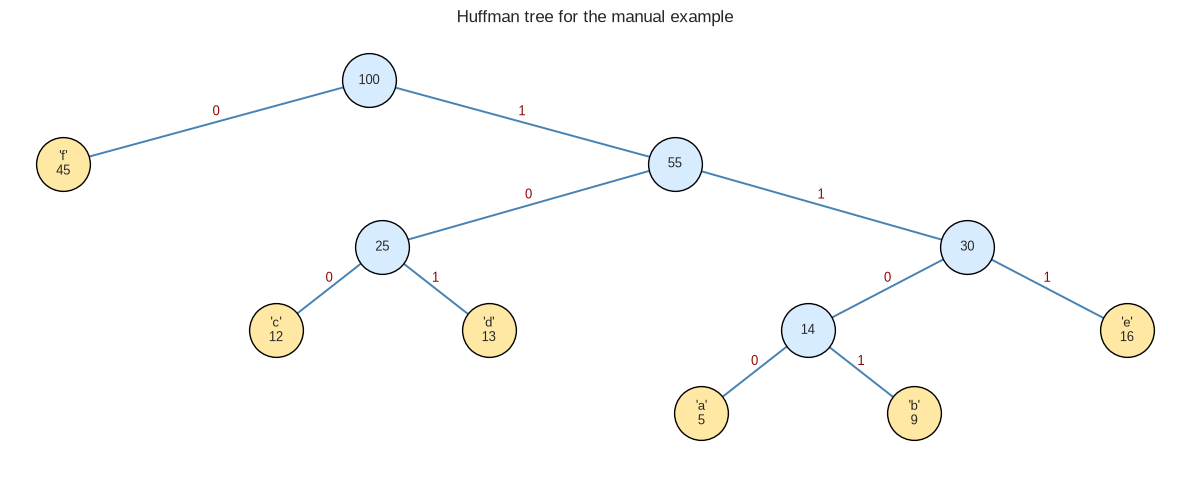

In [4]:
# Draw the Huffman tree. Leaf x-positions are assigned left-to-right; an
# internal node is placed above the average of its children.
def draw_huffman_tree(root: HuffmanNode, title: str = "Huffman tree") -> None:
    positions: dict[int, tuple[float, float]] = {}
    leaf_counter = [0]

    def assign(node: HuffmanNode, depth: int) -> float:
        if node.is_leaf():
            x = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            left_x = assign(node.left, depth + 1)
            right_x = assign(node.right, depth + 1)
            x = (left_x + right_x) / 2
        positions[id(node)] = (x, -depth)
        return x

    assign(root, 0)

    figure, axis = plt.subplots(figsize=(12, 5))
    max_depth = max(-y for _, y in positions.values())

    def draw_edges(node: HuffmanNode) -> None:
        if node.is_leaf():
            return
        x, y = positions[id(node)]
        for child, label in ((node.left, "0"), (node.right, "1")):
            child_x, child_y = positions[id(child)]
            axis.plot([x, child_x], [y, child_y], color="steelblue", linewidth=1.4)
            axis.text(
                (x + child_x) / 2,
                (y + child_y) / 2 + 0.05,
                label,
                ha="center",
                va="bottom",
                fontsize=9,
                color="darkred",
            )
            draw_edges(child)

    draw_edges(root)

    for node in _walk_nodes(root):
        x, y = positions[id(node)]
        if node.is_leaf():
            label = f"{node.char!r}\n{node.frequency}"
            colour = "#ffe8a3"
        else:
            label = str(node.frequency)
            colour = "#d7ecff"
        axis.scatter([x], [y], s=1500, color=colour, edgecolor="black", zorder=3)
        axis.text(x, y, label, ha="center", va="center", fontsize=9, zorder=4)

    axis.set_title(title)
    axis.set_ylim(-max_depth - 0.8, 0.6)
    axis.axis("off")
    plt.tight_layout()
    plt.show()


def _walk_nodes(node: HuffmanNode):
    """Yield every node of the tree in pre-order."""
    yield node
    if node.left is not None:
        yield from _walk_nodes(node.left)
    if node.right is not None:
        yield from _walk_nodes(node.right)


draw_huffman_tree(manual_root, "Huffman tree for the manual example")

### Encoding and decoding a real message

We now use the word `mississippi`. Its frequency table is:

| Character | Frequency |
|---|---|
| i | 4 |
| s | 4 |
| p | 2 |
| m | 1 |

The Huffman tree gives the two most frequent characters shorter codes. The
decoder must use exactly the same tree as the encoder.

In [5]:
message = "mississippi"
frequencies = dict(Counter(message))
root = build_huffman_tree(frequencies)
codes = build_code_table(root)

encoded = huffman_encode(message, codes)
decoded = huffman_decode(encoded, root)

print("Original message :", message)
print("Frequencies      :", frequencies)
print("Huffman codes    :", codes)
print("Encoded bits     :", encoded)
print("Decoded message  :", decoded)
print("Round-trip OK    :", decoded == message)

Original message : mississippi
Frequencies      : {'m': 1, 'i': 4, 's': 4, 'p': 2}
Huffman codes    : {'s': '0', 'm': '100', 'p': '101', 'i': '11'}
Encoded bits     : 100110011001110110111
Decoded message  : mississippi
Round-trip OK    : True


In [6]:
# Show the code table, encoded size and compression ratio.
total_symbols = len(message)
fixed_bits = total_symbols * math.ceil(math.log2(len(frequencies)))
huffman_bits = len(encoded)

summary = pd.DataFrame(
    [
        {"measure": "Distinct symbols", "value": len(frequencies)},
        {"measure": "Total symbols", "value": total_symbols},
        {"measure": "Fixed-length bits", "value": fixed_bits},
        {"measure": "Huffman bits", "value": huffman_bits},
        {"measure": "Bits saved", "value": fixed_bits - huffman_bits},
        {"measure": "Compression ratio", "value": f"{fixed_bits / huffman_bits:.2f}×"},
    ]
)
summary

,measure,value
0,Distinct symbols,4
1,Total symbols,11
2,Fixed-length bits,22
3,Huffman bits,21
4,Bits saved,1
5,Compression ratio,1.05×


In [7]:
# Longer text with spaces and punctuation: verify lossless round-trip.
sample_text = (
    "Huffman coding assigns shorter codes to more frequent characters. "
    "This is an example of a greedy algorithm!"
)
sample_frequencies = dict(Counter(sample_text))
sample_root = build_huffman_tree(sample_frequencies)
sample_codes = build_code_table(sample_root)
sample_encoded = huffman_encode(sample_text, sample_codes)
sample_decoded = huffman_decode(sample_encoded, sample_root)

print("Characters in text :", len(sample_text))
print("Distinct characters:", len(sample_frequencies))
print("Encoded bit length :", len(sample_encoded))
print("Decoded correctly  :", sample_decoded == sample_text)
print("\nFirst 100 encoded bits:")
print(textwrap.fill(sample_encoded[:100], 80))

Characters in text : 107
Distinct characters: 25
Encoded bit length : 453
Decoded correctly  : True

First 100 encoded bits:
11111001111000111101111110101010000110011011011001110010000011110010010101011101
10100111000001101110


In [8]:
# Test edge cases.
# 1. A one-character alphabet still has a valid (single) code.
single_root = build_huffman_tree({"x": 10})
single_codes = build_code_table(single_root)
single_encoded = huffman_encode("xxxx", single_codes)
print("Single-symbol code:", single_codes, "->", single_encoded)
assert huffman_decode(single_encoded, single_root) == "xxxx"

# 2. Empty input.
empty_root = build_huffman_tree({"a": 1, "b": 1})
assert huffman_decode("", empty_root) == ""

# 3. Invalid input.
try:
    build_huffman_tree({})
except ValueError as error:
    print("Empty alphabet ->", error)

try:
    build_huffman_tree({"a": 0})
except ValueError as error:
    print("Zero frequency ->", error)

print("\nAll edge-case tests passed ✓")

Single-symbol code: {'x': '0'} -> 0000
Empty alphabet -> At least one character is required
Zero frequency -> Frequencies must be positive integers

All edge-case tests passed ✓


In [9]:
# Compare Huffman with fixed-length coding for several messages.
comparison_rows = []
for text in [
    "mississippi",
    "abracadabra",
    "the quick brown fox jumps over the lazy dog",
    "aaaaaaaaaabbbbbcccdde",
]:
    frequency_map = dict(Counter(text))
    tree = build_huffman_tree(frequency_map)
    table = build_code_table(tree)
    encoded_bits = huffman_encode(text, table)
    fixed_length = math.ceil(math.log2(max(2, len(frequency_map))))
    comparison_rows.append(
        {
            "message": text[:35] + ("..." if len(text) > 35 else ""),
            "symbols": len(text),
            "alphabet": len(frequency_map),
            "fixed bits/symbol": fixed_length,
            "fixed bits": len(text) * fixed_length,
            "Huffman bits": len(encoded_bits),
            "saving %": round(
                100 * (1 - len(encoded_bits) / (len(text) * fixed_length)), 2
            ),
        }
    )

pd.DataFrame(comparison_rows)

,message,symbols,alphabet,fixed bits/symbol,fixed bits,Huffman bits,saving %
0,mississippi,11,4,2,22,21,4.55
1,abracadabra,11,5,3,33,23,30.30
2,the quick brown fox jumps over the ...,43,27,5,215,192,10.70
3,aaaaaaaaaabbbbbcccdde,21,5,3,63,41,34.92


In [10]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - DAA Practical 2 (Huffman coding)")
print("=" * 78)
print(
    "Huffman coding is a greedy algorithm. It repeatedly merges the two least\n"
    "frequent nodes, so frequent characters end up near the root and receive\n"
    "short codewords. The output below explains the code table, the round-trip\n"
    "test and the compression achieved."
)

print("\n1. MANUAL EXAMPLE (a=5, b=9, c=12, d=13, e=16, f=45)")
print("-" * 78)
manual_total_symbols = int(manual_table["frequency"].sum())
manual_huffman_bits = int(manual_table["bits used"].sum())
manual_fixed_bits = manual_total_symbols * math.ceil(math.log2(len(manual_frequencies)))
manual_table_sorted = manual_table.sort_values("frequency", ascending=False)
for _, row in manual_table_sorted.iterrows():
    print(
        f"  {row['character']!r}: frequency={int(row['frequency']):2d}, "
        f"code={row['codeword']:>4s}, length={int(row['code length'])}, "
        f"contribution={int(row['bits used'])} bits"
    )
print(f"Total Huffman bits : {manual_huffman_bits}")
print(f"Fixed-length bits  : {manual_fixed_bits} ({manual_total_symbols} symbols x 3 bits)")
print(f"Bits saved         : {manual_fixed_bits - manual_huffman_bits}")
print(f"Saving             : {100 * (1 - manual_huffman_bits / manual_fixed_bits):.2f}%")
print(f"Weighted average code length: {manual_huffman_bits / manual_total_symbols:.3f} bits/symbol")
print("Interpretation: 'f' occurs 45 times and gets a 1-bit code, while the")
print("rarer characters get 3-4 bit codes. The weighted average is below the")
print("fixed-length requirement of 3 bits per symbol.")

prefix_free = all(
    not (left != right and right.startswith(left))
    for left in manual_codes.values()
    for right in manual_codes.values()
)
print(f"Prefix-free property holds: {prefix_free}")

print("\n2. ENCODING AND DECODING 'mississippi'")
print("-" * 78)
print("Frequencies :", frequencies)
print("Codes       :", codes)
print("Encoded bits:", encoded)
print(f"Original symbols: {len(message)}, encoded bits: {len(encoded)}")
print(f"Decoded text: {decoded!r}")
print(f"Round-trip identical to the original: {decoded == message}")
print("Interpretation: decoding uses the same tree as encoding. Because the")
print("code is prefix-free, no separator is needed between codewords.")

print("\n3. COMPRESSION SUMMARY")
print("-" * 78)
print(f"Distinct symbols       : {len(frequencies)}")
print(f"Fixed-length bits       : {fixed_bits}")
print(f"Huffman bits            : {huffman_bits}")
print(f"Bits saved              : {fixed_bits - huffman_bits}")
print(f"Compression ratio       : {fixed_bits / huffman_bits:.2f}x")
print("Interpretation: the fixed-length code needs 2 bits for every symbol")
print("because there are four distinct symbols. Huffman uses fewer bits for the")
print("frequent letters and more for the rare ones, so the saving depends on how")
print("skewed the frequency distribution is.")

print("\n4. LONGER TEXT AND EDGE CASES")
print("-" * 78)
sample_fixed_bits = len(sample_text) * math.ceil(math.log2(len(sample_frequencies)))
print(f"Long sample: {len(sample_text)} characters, {len(sample_frequencies)} distinct")
print(f"Long sample encoded length: {len(sample_encoded)} bits")
print(f"Long sample fixed-length equivalent: {sample_fixed_bits} bits")
print(f"Long sample decoded correctly: {sample_decoded == sample_text}")
print(f"Single-symbol alphabet code: {single_codes} -> {single_encoded!r}")
print("The single-symbol example shows an important edge case: a leaf with no")
print("edge is assigned the code '0'. Empty and zero-frequency alphabets are")
print("rejected with ValueError instead of producing an invalid tree.")

print("\n5. COMPARISON ACROSS MESSAGES")
print("-" * 78)
comparison_df = pd.DataFrame(comparison_rows)
for _, row in comparison_df.iterrows():
    print(
        f"  {row['message']!r:40s} symbols={row['symbols']:2d}, "
        f"alphabet={row['alphabet']:2d}, saving={row['saving %']:5.2f}%"
    )
best_row = comparison_df.loc[comparison_df["saving %"].idxmax()]
print(
    f"Largest saving: {best_row['saving %']:.2f}% for {best_row['message']!r}; "
    "a skewed distribution is the best case for Huffman."
)
print("A nearly uniform alphabet gives little or no saving, because all")
print("codewords must then have similar lengths.")

print("\n6. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Building the min-heap       : O(n)")
print("n-1 greedy merges           : O(n log n)")
print("Generating codewords        : O(n)")
print("Encoding/decoding a text    : O(L), where L is the number of symbols/bits")
print("Space                       : O(n) for the tree, heap and code table")
print("The greedy choice is safe because the two least frequent symbols can")
print("always be placed at the deepest level of some optimal prefix tree.")

DETAILED OUTPUT EXPLANATION - DAA Practical 2 (Huffman coding)
Huffman coding is a greedy algorithm. It repeatedly merges the two least
frequent nodes, so frequent characters end up near the root and receive
short codewords. The output below explains the code table, the round-trip
test and the compression achieved.

1. MANUAL EXAMPLE (a=5, b=9, c=12, d=13, e=16, f=45)
------------------------------------------------------------------------------
  'f': frequency=45, code=   0, length=1, contribution=45 bits
  'e': frequency=16, code= 111, length=3, contribution=48 bits
  'd': frequency=13, code= 101, length=3, contribution=39 bits
  'c': frequency=12, code= 100, length=3, contribution=36 bits
  'b': frequency= 9, code=1101, length=4, contribution=36 bits
  'a': frequency= 5, code=1100, length=4, contribution=20 bits
Total Huffman bits : 224
Fixed-length bits  : 300 (100 symbols x 3 bits)
Bits saved         : 76
Saving             : 25.33%
Weighted average code length: 2.240 bits/symbol

### Observations

1. The most frequent character (`f`, frequency 45) gets the shortest code,
   `0`; rare characters get longer codes.
2. The code is a **prefix code**: no codeword is a prefix of another, so
   decoding is unambiguous without separators.
3. Huffman coding is **lossless**: the decoded text is exactly the original.
4. The greedy choice — always merge the two least frequent nodes — produces an
   optimal tree. The algorithm does not try every possible tree.
5. The saving depends on the frequency distribution. A very skewed
   distribution compresses well; a nearly uniform distribution gives little or
   no saving over fixed-length coding.

### Complexity analysis

Let $n$ be the number of distinct characters and $L$ the length of the
message.

- Building the heap: $O(n)$.
- Each of the $n-1$ merges performs two `heappop` and one `heappush`, each
  $O(\log n)$: total $O(n\log n)$.
- Generating the code table by a tree traversal: $O(n)$.
- Encoding/decoding: $O(L)$.
- Space: $O(n)$ for the tree, heap and code table.

If the input frequencies are already sorted, a linear-time two-queue
implementation is possible, giving $O(n)$ tree construction.

## 5. Conclusion

We successfully implemented Huffman encoding using a min-heap and a greedy
merge strategy. The generated codes are prefix-free, the encoded message can
be decoded without ambiguity, and the round-trip test confirms lossless
compression. The experiment also shows that Huffman coding reduces the number
of bits compared with a fixed-length code when the symbol frequencies are
uneven.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is a prefix code? | A code in which no codeword is a prefix of another codeword. |
| Why is a prefix code needed? | It allows decoding without separators between codewords. |
| What is the greedy choice in Huffman coding? | Merge the two nodes with the smallest frequencies. |
| Why is Huffman coding optimal? | The two least frequent symbols can always be placed at the deepest level; merging them preserves optimality. |
| What data structure is used? | A min-heap (priority queue). |
| What is the time complexity? | $O(n\log n)$ for $n$ distinct characters. |
| Is Huffman coding lossless? | Yes; the original bit stream is recovered exactly. |
| Where is Huffman coding used? | ZIP/GZIP, JPEG, PNG, MP3 and other compression formats. |
| What happens if all frequencies are equal? | The tree is balanced and the code length is close to $\lceil\log_2 n\rceil$. |
| Can a Huffman code be decoded without the tree? | Yes, if the code table is transmitted; otherwise the tree (or code lengths) must be stored. |